# SET-UP

The project repository can be found [here](https://github.com/n-sharan/dataset-diversity-generalization/tree/main
)

The DBIsubset and SDDsubset can be found in the repository under the data folder:

*   DBIsubset: https://github.com/n-sharan/dataset-diversity-generalization/blob/main/data/DBIsubset.zip

*   SDDsubset: https://github.com/n-sharan/dataset-diversity-generalization/blob/main/data/DBIsubset.zip

This notebook is hosted on Google Colab, thus in order to run the code blocks, the repository will first be cloned into the Colab environment.
The analysis will use the source code in the repository as expected.


In [1]:
import os
import torch
import torchvision
from torchvision import models
from torch import nn

In [2]:
!git clone https://github.com/n-sharan/dataset-diversity-generalization.git
os.chdir('/content/dataset-diversity-generalization')

# unzip if folders don't already exist
if not os.path.exists('DBIsubset'):
    !unzip -qq data/DBIsubset.zip -d data/
    !rm data/DBIsubset.zip
else:
    print('DBIsubset folder already exists')

if not os.path.exists('SDDsubset'):
    !unzip -qq data/SDDsubset.zip -d data/
    !rm data/SDDsubset.zip
else:
    print('SDDsubset folder already exists')

Cloning into 'dataset-diversity-generalization'...
remote: Enumerating objects: 65, done.
remote: Counting objects: 100% (24/24), done.
remote: Compressing objects: 100% (23/23), done.
remote: Total 65 (delta 11), reused 3 (delta 1), pack-reused 41 (from 2)
Receiving objects: 100% (65/65), 110.04 MiB | 43.20 MiB/s, done.
Resolving deltas: 100% (16/16), done.


## Loading Datasets

The source code for the DataManager class can be found in the repository in [src/data_manager.py](https://github.com/n-sharan/dataset-diversity-generalization/blob/main/src/data_manager.py)

The DataManager class is instantiated with a given batch size (standard value of 128), and a series of transformations are defined.
In the ```get_loader``` function, a given dataset is processed with the defined set of transformations and the given batch size, and produces loaders for the training data split, validation split, and test split.

In [3]:
from src.data_manager import DataManager

data_manager = DataManager(batch_size=128)
SDD_train_loader,SDD_val_loader,SDD_test_loader = data_manager.get_loader("data/SDDsubset")
DBI_train_loader,DBI_val_loader,DBI_test_loader = data_manager.get_loader("data/DBIsubset")

## Loading Models

This report analyses performance across 7 types of models:
1. CNN trained using dropout
2. CNN trained without using dropout
3. ResNet18 without pre-trained weights
4. ResNet18 with pre-trained weights
5. ResNet34 with pre-trained weights
6. ResNet50 with pre-trained weights
7. ResNext50 with pre-trained weights


The source code for the CNN class can be found in the repository in [src/simple_cnn.py](https://github.com/n-sharan/dataset-diversity-generalization/blob/main/src/simple_cnn.py)

The CNN is defined with 4 convolutional layers, and a final classifier layer.

The pre-trained ResNet models are modified such that the last layer matches the number of classes in the dataset.

In [4]:
from src.simple_cnn import SimpleCNN

net_dp = SimpleCNN()
net_wdp = SimpleCNN()

In [5]:
mod_resnet18_nopt = models.resnet18(weights=None)
mod_resnet18_nopt.fc = nn.Linear(mod_resnet18_nopt.fc.in_features, 7)

In [6]:
from torchvision.models import ResNet50_Weights, ResNeXt50_32X4D_Weights

mod_resnet18 = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
mod_resnet34 = models.resnet34(weights=models.ResNet34_Weights.DEFAULT)
mod_resnext50 = models.resnext50_32x4d(weights=ResNeXt50_32X4D_Weights.DEFAULT)
mod_resnet50 = models.resnet50(weights=ResNet50_Weights.DEFAULT)

pt_models = [mod_resnet18, mod_resnet34, mod_resnext50, mod_resnet50]

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 106MB/s]


Downloading: "https://download.pytorch.org/models/resnet34-b627a593.pth" to /root/.cache/torch/hub/checkpoints/resnet34-b627a593.pth


100%|██████████| 83.3M/83.3M [00:00<00:00, 143MB/s]


Downloading: "https://download.pytorch.org/models/resnext50_32x4d-1a0047aa.pth" to /root/.cache/torch/hub/checkpoints/resnext50_32x4d-1a0047aa.pth


100%|██████████| 95.8M/95.8M [00:00<00:00, 155MB/s]


Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 157MB/s]


In [13]:
for model in pt_models:
  for param in model.parameters():
      param.requires_grad = False

  input_size = model.fc.in_features
  model.fc = nn.Sequential(nn.Linear(input_size, 256), nn.ReLU(), nn.Dropout(0.2),nn.Linear(256, 7), nn.Softmax(dim=1))

# Model Architectures

This section displays the layers of the 5 base architectures:
CNN, ResNet18, ResNet34, ResNet50, ResNext50

In [14]:
net_dp

SimpleCNN(
  (conv1): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv2): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv3): Conv2d(16, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn2): BatchNorm2d(8, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv4): Conv2d(8, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (fc1): Linear(in_features=25088, out_features=32, bias=True)
  (fc2): Linear(in_features=32, out_features=7, bias=True)
  (dropout): Dropout(p=0.4, inplace=False)
)

In [15]:
mod_resnet18_nopt

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

In [16]:
mod_resnet18

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

In [17]:
mod_resnet34

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

In [18]:
mod_resnet50

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 

In [19]:
mod_resnext50

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 128, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
      (bn2): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv3): Conv2d(128, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Conv2d(64, 256, kernel_size=(1

## Model Stats

In [30]:
model_names = ["net_dp", "net_wdp", "resnet18_nopt", "resnet18", "resnet34", "resnet50", "resnext50"]
model_list = [net_dp, net_wdp, mod_resnet18_nopt, mod_resnet18, mod_resnet34, mod_resnet50, mod_resnext50]
model_titles = [
    "CNN with Dropout",
    "CNN without Dropout",
    "ResNet18 no Pretrained Weights",
    "ResNet18",
    "ResNet34",
    "ResNet50",
    "ResNext50"
]

model_info = {name: {"model": model_list[i], "title": model_titles[i], "stats": {}} for i, name in enumerate(model_names)}

In [190]:
for name in model_info: print(f"{name}: {{model: {type(model_info[name]["model"])}, stats: {model_info[name]["stats"]}, title: {model_info[name]["title"]}}}")

net_dp: {model: <class 'src.simple_cnn.SimpleCNN'>, stats: {'train': [16, 26, 32, 34, 36, 37, 42, 39, 41, 41], 'val': [28, 32, 34, 35, 34, 37, 31, 35, 37, 31], 'test': 35}, title: CNN with Dropout}
net_wdp: {model: <class 'src.simple_cnn.SimpleCNN'>, stats: {'train': [13, 16, 17, 21, 24, 28, 38, 36, 36, 37], 'val': [12, 14, 21, 17, 18, 18, 25, 20, 18, 21], 'test': 32}, title: CNN without Dropout}
resnet18_nopt: {model: <class 'torchvision.models.resnet.ResNet'>, stats: {'train': [22, 37, 48, 51, 58, 65, 73, 71, 70, 76], 'val': [20, 37, 18, 28, 45, 34, 25, 21, 29, 26], 'test': 41}, title: ResNet18 no Pretrained Weights}
resnet18: {model: <class 'torchvision.models.resnet.ResNet'>, stats: {'train': [19, 32, 44, 57, 65, 72, 81, 84, 85, 86], 'val': [29, 34, 51, 59, 70, 78, 82, 78, 79, 79], 'test': 80}, title: ResNet18}
resnet34: {model: <class 'torchvision.models.resnet.ResNet'>, stats: {'train': [18, 37, 45, 58, 64, 67, 73, 82, 87, 88], 'val': [34, 43, 51, 62, 71, 76, 79, 87, 82, 87], 'te

In [183]:
model_type_split = 2

# Training

Define the Trainer class based on the DBI dataset.

In [205]:
from src.trainer import Trainer

dbi_trainer = Trainer(DBI_train_loader, DBI_val_loader, DBI_test_loader)

Define an experiment function to save the results to the model information.

In [158]:
def run_training(model_name, lr, dropout=True):
    model = model_info[model_name]["model"]
    res = {}

    res["train"], res["val"], res["test"] = dbi_trainer.train(model=model, lr=lr, with_dropout=dropout)
    model_info[model_name]["stats"] = res

Define the learning rates for the CNN based models, and the ResNet models.

In [20]:
cnn_lr = 0.001
res_lr = 0.0003

Define list of models with ResNet architecture.

In [184]:
res_models = model_names[model_type_split:]

## CNN Based Models

In this section, two identical CNN models are trained such that one is trained using dropout, and the other is trained without dropout.

Dropout is a regularization technique that randomly freezes a fraction of units in a neural network. It is used to reduce overfitting.

The hypothesis is that the model trained with dropout will have a better ability to generalize compared to the one trained without dropout.



### Training with Dropout

In [139]:
run_training(
    model_name="net_dp",
    lr=cnn_lr,
    dropout=True
)

Epoch 1: training accuracy: 16%, validation accuracy 28%
Epoch 2: training accuracy: 26%, validation accuracy 32%
Epoch 3: training accuracy: 32%, validation accuracy 34%
Epoch 4: training accuracy: 34%, validation accuracy 35%
Epoch 5: training accuracy: 36%, validation accuracy 34%
Epoch 6: training accuracy: 37%, validation accuracy 37%
Epoch 7: training accuracy: 42%, validation accuracy 31%
Epoch 8: training accuracy: 39%, validation accuracy 35%
Epoch 9: training accuracy: 41%, validation accuracy 37%
Epoch 10: training accuracy: 41%, validation accuracy 31%
---------------------------------------------------------
Finished Training
final training accuracy: 41%
final validation accuracy: 31%
final test accuracy: 35%


### Training Without Dropout

In [140]:
run_training(
    model_name="net_wdp",
    lr=cnn_lr,
    dropout=False
)

Epoch 1: training accuracy: 13%, validation accuracy 12%
Epoch 2: training accuracy: 16%, validation accuracy 14%
Epoch 3: training accuracy: 17%, validation accuracy 21%
Epoch 4: training accuracy: 21%, validation accuracy 17%
Epoch 5: training accuracy: 24%, validation accuracy 18%
Epoch 6: training accuracy: 28%, validation accuracy 18%
Epoch 7: training accuracy: 38%, validation accuracy 25%
Epoch 8: training accuracy: 36%, validation accuracy 20%
Epoch 9: training accuracy: 36%, validation accuracy 18%
Epoch 10: training accuracy: 37%, validation accuracy 21%
---------------------------------------------------------
Finished Training
final training accuracy: 37%
final validation accuracy: 21%
final test accuracy: 32%


## ResNet Models

In this section, a ResNet18 model without pre-trained weights is trained from scratch using the DBI dataset. It's performance is compared to the CNN model.
The performance of 4 pretrained ResNet based models are also trained and evaluated on the DBI dataset.
1. ResNet18
2. ResNet34
3. ResNet50
4. ResNext50

In [157]:
for name in res_models:
    print(f"[TRAINING {name}]")
    run_training(
        model_name=name,
        lr=res_lr,
        dropout=True
    )
    print("\n\n")

[TRAINING resnet18_nopt]
Epoch 1: training accuracy: 22%, validation accuracy 20%
Epoch 2: training accuracy: 37%, validation accuracy 37%
Epoch 3: training accuracy: 48%, validation accuracy 18%
Epoch 4: training accuracy: 51%, validation accuracy 28%
Epoch 5: training accuracy: 58%, validation accuracy 45%
Epoch 6: training accuracy: 65%, validation accuracy 34%
Epoch 7: training accuracy: 73%, validation accuracy 25%
Epoch 8: training accuracy: 71%, validation accuracy 21%
Epoch 9: training accuracy: 70%, validation accuracy 29%
Epoch 10: training accuracy: 76%, validation accuracy 26%
---------------------------------------------------------
Finished Training
final training accuracy: 76%
final validation accuracy: 26%
final test accuracy: 41%



[TRAINING resnet18]
Epoch 1: training accuracy: 19%, validation accuracy 29%
Epoch 2: training accuracy: 32%, validation accuracy 34%
Epoch 3: training accuracy: 44%, validation accuracy 51%
Epoch 4: training accuracy: 57%, validation accur

# Evaluation on SDD

In this section, the trained ResNet based models will be evaluated on the SDD dataset.

The SDD dataset has greater visual diversity in terms of positioning, occlusion, clarity and other factors, in comparison to the DBI dataset.

The hypothesis is that the test peformance on the SDD dataset will be worse than the DBI dataset.

Define the evaluator.

In [204]:
sdd_eval = Trainer(SDD_train_loader, SDD_val_loader, SDD_test_loader)

Define the helper function for running evaluation.

In [213]:
def run_eval_sdd(model_name):
    model = model_info[model_name]["model"]
    res = {}

    acc = sdd_eval.get_accuracy(loader=SDD_test_loader, model=model)
    model_info[model_name]["stats"]["SDD_acc"] = acc
    return acc

Evaluating the Resnet18 model without the pretrained weights.

In [210]:
name = "resnet18_nopt"
acc = run_eval_sdd(name)
print(f"{model_info[name]["title"]}: \t {acc}%")

ResNet18 no Pretrained Weights: 	 28%


Evaluating the pretrained ResNet models.

In [211]:
for name in res_models_pt:
    acc = run_eval_sdd(name)
    print(f"{model_info[name]["title"]}: \t {acc}%")

ResNet18: 	 81%
ResNet34: 	 80%
ResNet50: 	 86%
ResNext50: 	 90%


# Analysis

In this section, the performance of the models across the DBI and SDD datasets are analysed.

Define helper functions for line graphs.

In [200]:
import matplotlib.pyplot as plt

def build_subplot(ax, x, y1, y2, title):
    ax.plot(x, y1, label='training', color='blue', marker='o')
    ax.plot(x, y2, label='validation', color='purple', marker='x')
    ax.set_xlabel('epochs')
    ax.set_ylabel('accuracy')
    ax.set_title(title)
    ax.legend()

def build_figure(models):
    num_plots = len(models)
    x = list(range(10))
    fig, ax_lst = plt.subplots(1, num_plots, figsize=(20, 5))

    for i, name in enumerate(models):
        ax = ax_lst[i]
        y1 = model_info[name]["stats"]["train"]
        y2 = model_info[name]["stats"]["val"]
        title = model_info[name]["title"]
        print(f"{title} Test Accuracy: {model_info[name]["stats"]["test"]}")
        build_subplot(ax, x, y1, y2, title)
    plt.tight_layout()
    plt.show()

## DBI Accuracies

### CNN Models: Dropout vs No Dropout

In this section the training behaviour and accuracies of the two CNN models are compared. The hypothesis was that the model trained with dropout would perform better.

This hypthesis is confirmed by the data.
For the model without dropout, there appears to be a greater disparity between the training and validation accuracy, implying that performance on the training split is improving, while performance on the validation split does not appear to benefit much across epochs.

On the other hand, the model with dropout appears to improve its performance across epochs for both training and validation splits.

Based on this, it appears the model with dropout has acheieved better generalization compared to the model without dropout.

This is because dropout is a regularization technique that prevents units in neural layers from adapting too closely to patterns in training data. It reduces the chances of overfitting as a result, which overall improves generalization.

CNN with Dropout Test Accuracy: 35
CNN without Dropout Test Accuracy: 32


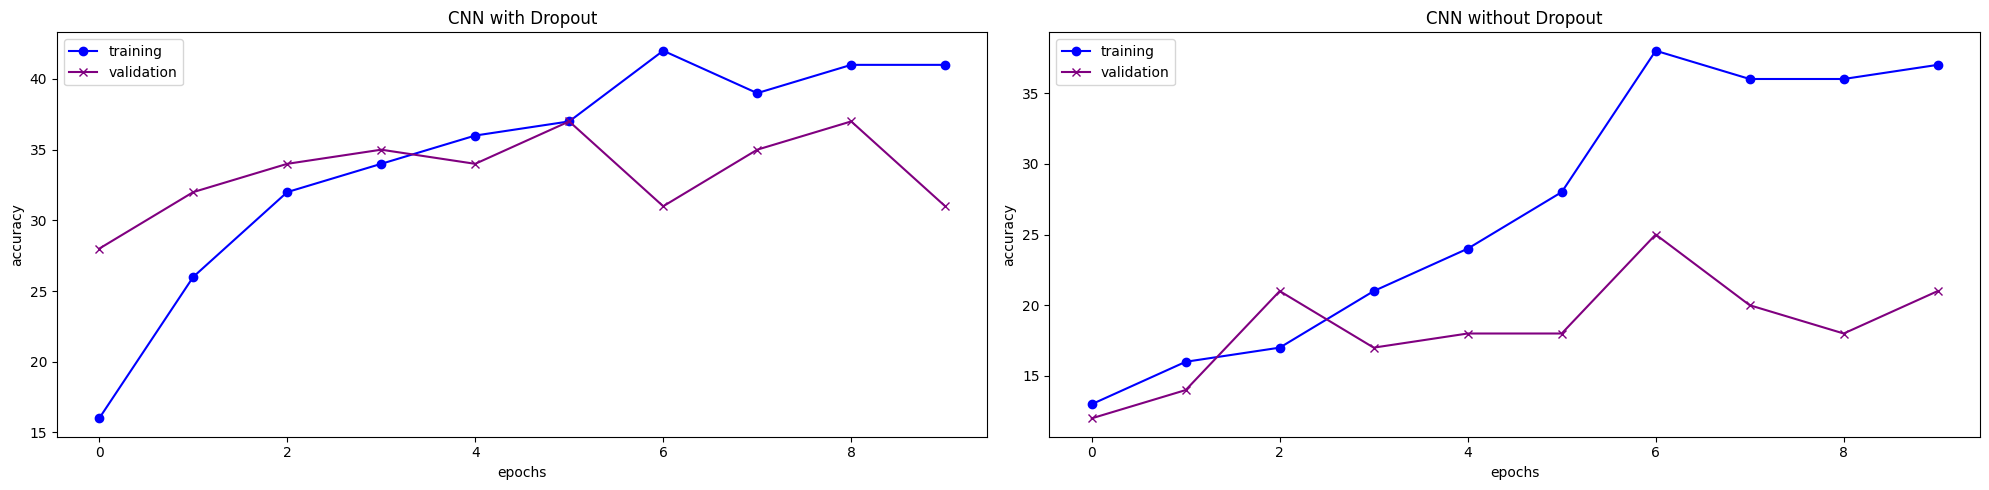

In [201]:
cnn_models = model_names[:model_type_split]
build_figure(cnn_models)

### CNN vs ResNet18 (no pre-trained weights)

In this section the performances of the CNN model and the ResNet18 model are compared. Based on the results of the training across the epochs, it appears that ResNet18 is overfitting across the training data, as there is a growing disparity between the training accuracy and validation accuracy.
This is likely because the ResNet architecture has a lot more weights and parameters that can adjust to the training data. Since this larger architecture has been trained on a dataset with limited diversity (DBI) it has likely overfit on this data. While the CNN has fewer weights and a more simple architecture, it can generalize better with this dataset.

CNN with Dropout Test Accuracy: 35
ResNet18 no Pretrained Weights Test Accuracy: 41


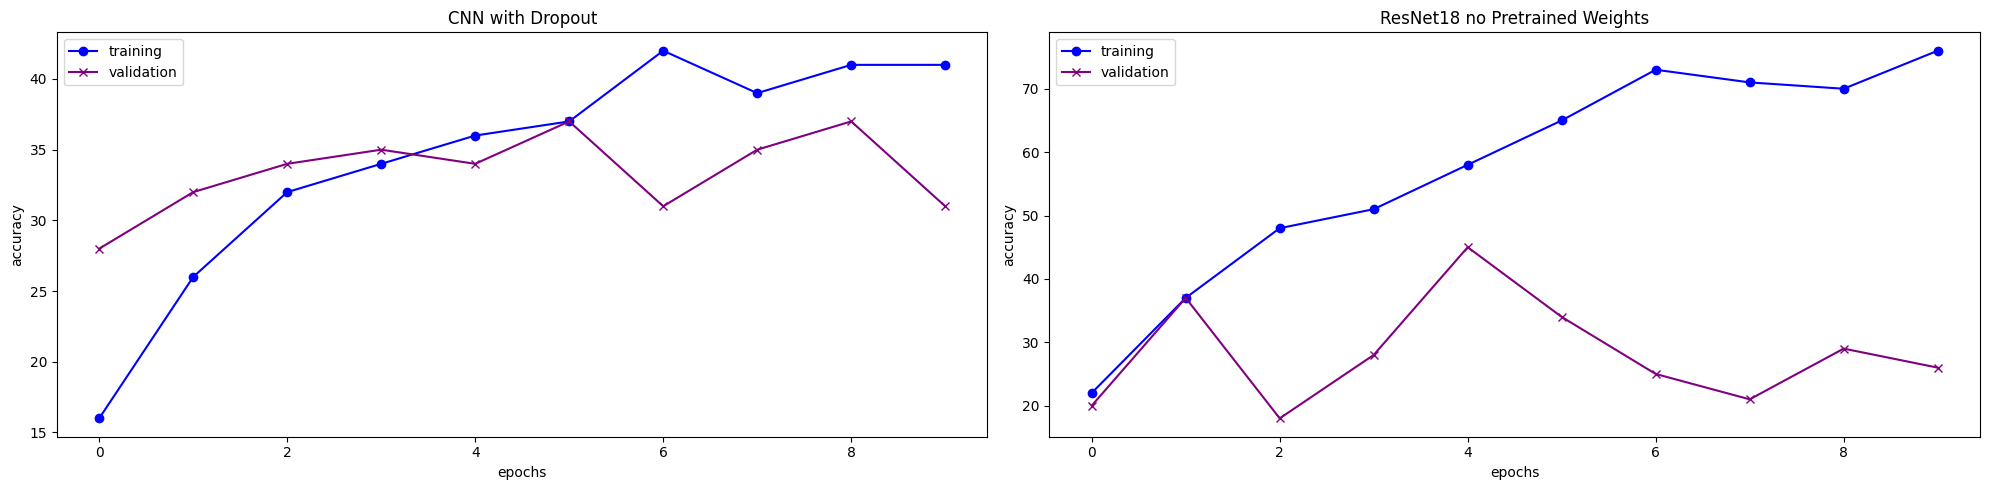

In [202]:
comp_models_cnn_res = ["net_dp", "resnet18_nopt"]
build_figure(comp_models_cnn_res)

### Pretrained ResNet Models

In this section, the performance of 4 pretrained ResNet Models are compared.

ResNet18 has the lowest accuracy at 80%, while ResNet50 and ResNext50 have the highest at 93%. The range of accuracy is relatively minimal when compared to the accuracy acheived by the models without pretraining, and fewer weights.

The performance of the models appears to correspond to the number of layers.
The reason the pretrained models with more weights performed better than the ones with fewer layers and weights, is likely because there were more parameters available to adjust to the patterns in the training data.

ResNet18 Test Accuracy: 80
ResNet34 Test Accuracy: 84
ResNet50 Test Accuracy: 93
ResNext50 Test Accuracy: 93


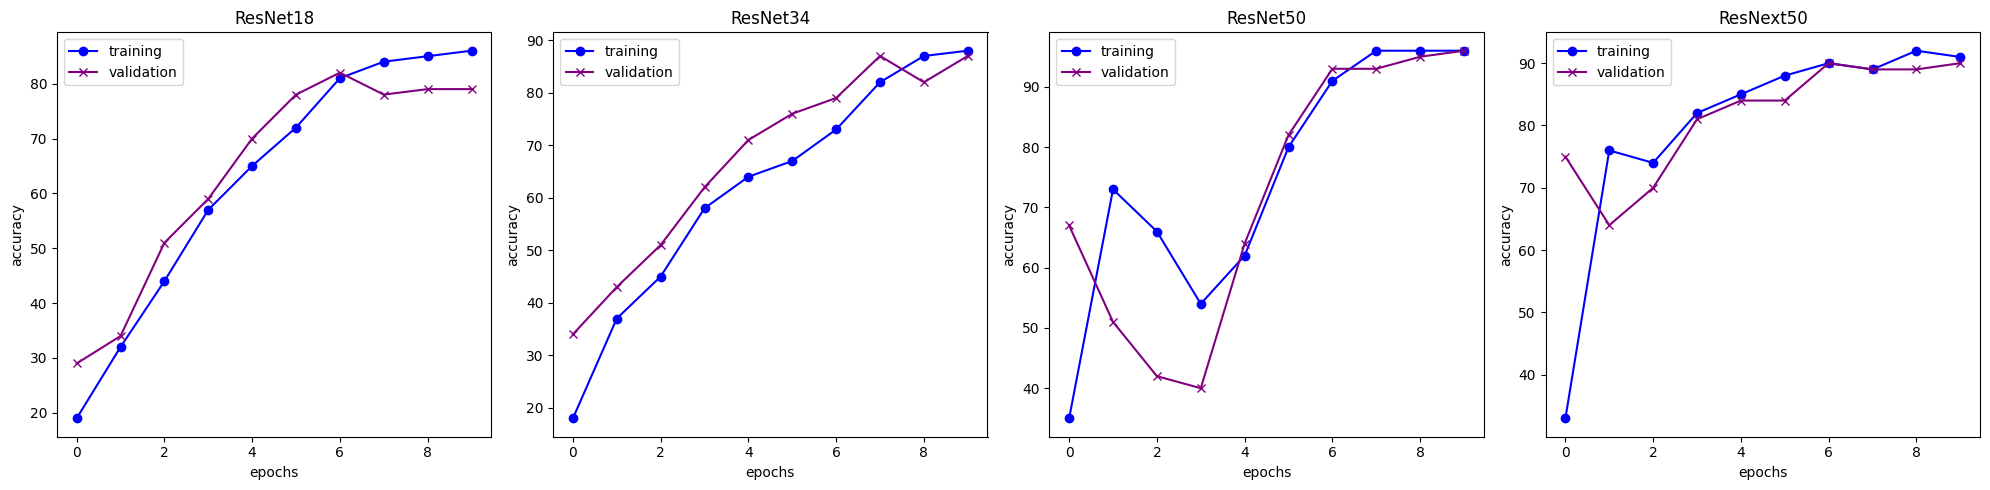

In [203]:
res_models_pt = model_names[model_type_split+1:]
build_figure(res_models_pt)

## SDD Accuracies

In this section, the test accuracies on the SDD dataset across the ResNet models are compared.

The ResNet18 model without pretraining acheives the lowest test accuracy on SDD, and the SDD accuracy is lower than on DBI. As it was established in the previous section, this model seemed to have overfit on the training data, and its generalization is therefore very poor.

The pretrained ResNet models acheived a much higher accuracy in comparison. The values for accuracies across SDD and DBI are similar, and while the performance is generally lower on SDD, the margin is a lot smaller, differing by 7% at maximum, and at minimum 1%, as well as 1% better in the case of ResNet18.

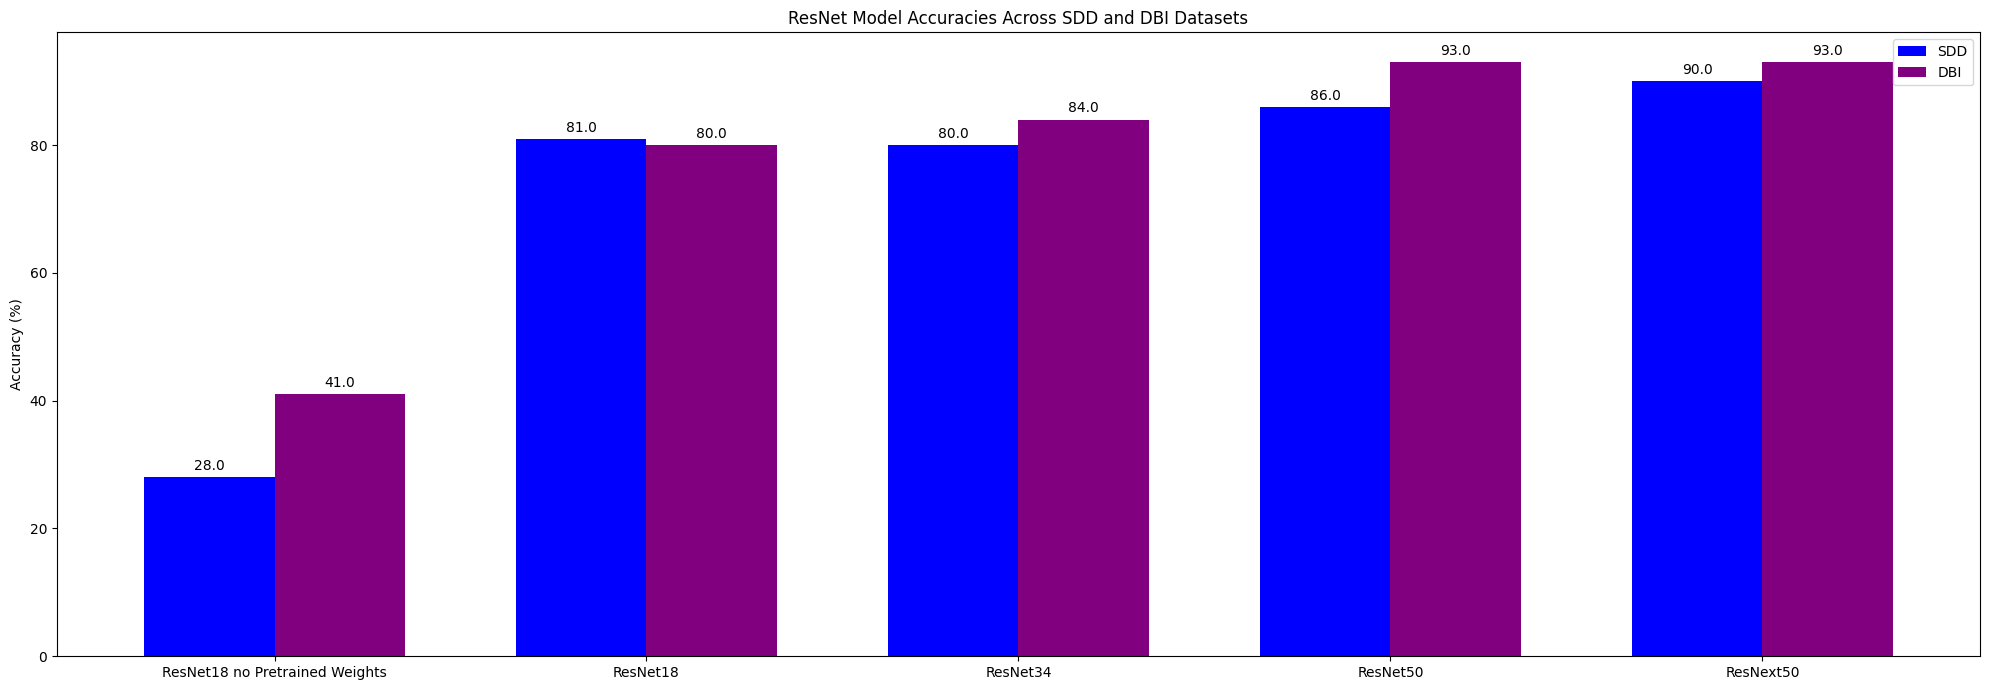

In [228]:
import numpy as np

sdd_accuracies = [model_info[name]["stats"]["SDD_acc"] for name in res_models]
dbi_accuracies = [model_info[name]["stats"]["test"] for name in res_models]
titles = [model_info[name]["title"] for name in res_models]

x = np.arange(len(res_models))
width = 0.35

fig, ax = plt.subplots(figsize=(20, 7))

bars1 = ax.bar(
    x - width/2, sdd_accuracies, width,
    label="SDD", color="blue"
)
bars2 = ax.bar(
    x + width/2, dbi_accuracies, width,
    label="DBI", color="purple"
)

ax.bar_label(bars1, fmt="%.1f", padding=3)
ax.bar_label(bars2, fmt="%.1f", padding=3)

ax.set_ylabel("Accuracy (%)")
ax.set_title("ResNet Model Accuracies Across SDD and DBI Datasets")
ax.set_xticks(x)
ax.set_xticklabels(titles)
ax.legend()

plt.tight_layout()
plt.show()